# IS630: Green Light for an Indie Studio
## Notebook 04: AQ3, What Factors Seem to Be the Most Important for a Game?
**Group**: [Insert names]

> **AI Coding Assistant Declaration**:
> An AI coding assistant wrote the code in this notebook and drafted its method at the group's direction, including the factor blocks, the draft split into controllable and not controllable factors, the per 2 SD scaling and the reduced-model rule, which keeps controllable factors only. The group must review and accept these before submission. Every code section is labelled as AI-generated. All interpretations, evaluations of model performance and conclusions are written by group members in the designated cells.

**AQ3** (group wording): *What factors seem to be the most important for a game? We want to study if there are certain factors that are especially important that determine the success of a game, and highlight ones that a studio can control.*

Success is the log completion ratio, as in notebook 03. This notebook reuses notebook 03's sample, predictors, standardisation, OLS model and Bayesian model through `src/is630/models.py`, so a factor's importance is read off the same fits that AQ2 evaluated.

| Section | Content |
|---|---|
| 1 | Factor map: blocks, and controllable or not |
| 2 | Effect sizes on a common scale, both models |
| 3 | Permutation importance on validation |
| 4 | Agreement between measures, and robustness |
| 5 | Reduced model on the clearest blocks |
| 6 | Effects a studio can read, on the completion-ratio scale |

**Reads:** `data/processed/02_train.parquet`, `data/processed/02_validation.parquet`, `data/processed/02_feature_spec.json`, `outputs/tables/03_aq2_influence_refits.csv`, `outputs/tables/03_aq2_vif.csv`, `outputs/tables/03_aq2_bayes_summary.csv`
**Writes:** `data/interim/04_aq3_importance.parquet`, tables `outputs/tables/04_aq3_*.csv`, figures `outputs/figures/04_aq3_*.png`

The test holdout from notebook 00 is never loaded here.

**Decisions taken from the spec defaults, for the group to confirm:** the controllable column in section 1, the per 2 SD scaling in section 2, and the reduced-model rule in section 5. Each is a single line of code to change.

**Limits that apply to every result:** the data are observational, so an effect is an association within story-driven, HowLongToBeat-matched games with at least 50 reviews and 5 polls, not the effect of changing the factor. Price is the price at scrape time, not the launch price. The numerator of the ratio, SteamSpy's median playtime, is an estimate with no sample size behind it.

## Setup
*Code: Generated by AI Assistant*

*Written by AI Assistant*: refits notebook 03's OLS model and Bayesian model with the same data, priors and seed. The Bayesian traces are not stored between notebooks, so it is sampled again here. The last lines compare its posterior means with the table notebook 03 saved, as a check that both notebooks describe the same fit.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
import pymc as pm
import arviz as az

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()) / "src"))
from is630 import config
from is630.models import COMPLETION_PRIORS, SAMPLE_KW, completion_model, completion_sample

for d in (config.FIGURES, config.TABLES):
    d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
rng = np.random.default_rng(config.SEED)

def save_fig(fig, name):
    # Write a figure to outputs/figures at 300 dpi.
    fig.savefig(config.FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")

df_train = pd.read_parquet(config.PROCESSED / "02_train.parquet")
df_val = pd.read_parquet(config.PROCESSED / "02_validation.parquet")
with open(config.PROCESSED / "02_feature_spec.json", encoding="utf-8") as f:
    FEATURES = json.load(f)["model_features"]

s = completion_sample(df_train, df_val, FEATURES)
X_train, X_val, y_train, y_val = s.X_train, s.X_val, s.y_train, s.y_val
print(f"rows in: {len(df_train):,} / {len(df_val):,}; completion model sample: {len(y_train):,} train, {len(y_val):,} validation")

clusters = pd.factorize(s.train["developer_group"])[0]
Xc_train = sm.add_constant(X_train, has_constant="add")
ols = sm.OLS(y_train, Xc_train).fit(cov_type="cluster", cov_kwds={"groups": clusters})

with completion_model(X_train, y_train, s.dev_train, s.inv_polls_train, len(s.dev_levels), COMPLETION_PRIORS):
    idata = pm.sample(**SAMPLE_KW)
summ = az.summary(idata, var_names=["intercept", "beta", "sigma", "tau", "sigma_dev"])
divergences = int(np.asarray(idata.sample_stats["diverging"]).sum())
converged = summ["r_hat"].max() < 1.01 and summ["ess_bulk"].min() > 400 and summ["ess_tail"].min() > 400 and divergences == 0
print(f"max r_hat {summ['r_hat'].max():.3f}, min ess_bulk {summ['ess_bulk'].min():.0f}, divergences {divergences} -> "
      f"{'converged' if converged else 'NOT CONVERGED'}")
saved = pd.read_csv(config.TABLES / "03_aq2_bayes_summary.csv", index_col=0)
print(f"largest difference from notebook 03's posterior means: {(summ['mean'] - saved.loc[summ.index, 'mean']).abs().max():.4f}")

def flat(trace, name):
    # Posterior draws with chains stacked: (draws, values).
    a = np.asarray(trace.posterior[name])
    return a.reshape(a.shape[0] * a.shape[1], -1)

g++ not available, if using conda: `conda install gxx`


rows in: 4,224 / 1,057; completion model sample: 1,927 train, 482 validation


NUTS[numpyro]: [intercept, beta, sigma_dev, z_dev, sigma, tau]


C:\Users\leesi\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


max r_hat 1.004, min ess_bulk 941, divergences 0 -> converged
largest difference from notebook 03's posterior means: 0.0000


## 1. Factor map
*Code: Generated by AI Assistant*

*Written by AI Assistant*: every predictor is put in one block, a group of columns that describe one decision, so that sets such as genres or store features are read together. The `controllable` column marks whether a studio sets the factor before launch. It is a draft: `not controllable` holds game age, the developer's other games on Steam and a missing-genre flag. The group should check in particular `flag_self_published`, which depends on whether a publisher deal is available, and `genre_early_access`, which is a release model rather than a genre.

In [2]:
BLOCKS = {
    "price": ["feature_log_price", "flag_free_to_play"],
    "release timing": ["flag_q4_release"],
    "platforms": ["steam_mac", "steam_linux"],
    "localisation": ["feature_log_language_count_imputed", "feature_log_audio_language_count", "flag_has_full_audio"],
    "store features": ["feature_log_achievements", "flag_has_achievements", "cat_multiplayer", "cat_coop",
                       "cat_controller", "cat_steam_cloud", "cat_trading_cards", "cat_vr"],
    "genre": [f for f in FEATURES if f.startswith("genre_")],
    "content rating": ["flag_age_restricted"],
    "publishing": ["flag_self_published"],
    "storefront": ["flag_has_website", "flag_has_support_contact"],
    "not controllable": ["steam_years_since_release", "feature_log_dev_game_count", "flag_missing_genre"],
}
LABELS = {
    "feature_log_price": "price (log)", "flag_free_to_play": "free to play", "flag_q4_release": "Q4 release",
    "steam_mac": "Mac version", "steam_linux": "Linux version",
    "feature_log_language_count_imputed": "interface languages (log)", "feature_log_audio_language_count": "audio languages (log)",
    "flag_has_full_audio": "full audio in any language", "feature_log_achievements": "achievements (log)",
    "flag_has_achievements": "has achievements", "cat_multiplayer": "multiplayer", "cat_coop": "co-op",
    "cat_controller": "controller support", "cat_steam_cloud": "Steam Cloud", "cat_trading_cards": "trading cards",
    "cat_vr": "VR", "flag_age_restricted": "age restricted", "flag_self_published": "self-published",
    "flag_has_website": "has website", "flag_has_support_contact": "has support contact",
    "steam_years_since_release": "years since release", "feature_log_dev_game_count": "developer's other games (log)",
    "flag_missing_genre": "genre missing",
}
block_of = {f: b for b, cols in BLOCKS.items() for f in cols}
assert sorted(block_of) == sorted(FEATURES), "every predictor must sit in exactly one block"

factor_map = pd.DataFrame({
    "label": [LABELS.get(f, f.replace("genre_", "genre: ").replace("_", " ")) for f in FEATURES],
    "block": [block_of[f] for f in FEATURES],
    "controllable": [block_of[f] != "not controllable" for f in FEATURES],
    "type": ["continuous" if f in s.continuous else "binary" for f in FEATURES],
}, index=pd.Index(FEATURES, name="feature"))
factor_map.to_csv(config.TABLES / "04_aq3_factor_map.csv")
print(factor_map.groupby(["block", "controllable"]).size().rename("predictors").to_string())
factor_map

block             controllable
content rating    True            1
genre             True            8
localisation      True            3
not controllable  False           3
platforms         True            2
price             True            2
publishing        True            1
release timing    True            1
store features    True            8
storefront        True            2


,label,block,controllable,type
feature,,,,
feature_log_price,price (log),price,True,continuous
flag_free_to_play,free to play,price,True,binary
steam_years_since_release,years since release,not controllable,False,continuous
flag_q4_release,Q4 release,release timing,True,binary
steam_mac,Mac version,platforms,True,binary
steam_linux,Linux version,platforms,True,binary
feature_log_language_count_imputed,interface languages (log),localisation,True,continuous
feature_log_audio_language_count,audio languages (log),localisation,True,continuous
flag_has_full_audio,full audio in any language,localisation,True,binary


## 2. Effect sizes on a common scale
*Code: Generated by AI Assistant*

*Written by AI Assistant*: in notebook 03 a continuous coefficient is per standard deviation and a binary one is per switch from 0 to 1, so the two are not on the same footing. Here continuous effects are doubled to per 2 SD, which makes them roughly comparable with a binary predictor that is on for about half the games. Each effect is a change in the log completion ratio, and `multiplier = exp(effect)` is the factor by which the ratio changes.

For each predictor: the OLS estimate with its developer-clustered 95% CI and Benjamini-Hochberg q, and the Bayesian posterior mean with its 95% credible interval and the posterior probability of its sign. `clear_in_both` marks predictors with q < 0.05 in OLS and a credible interval that excludes zero.

In [3]:
PER = pd.Series(1.0, index=FEATURES)
PER[s.continuous] = 2.0                                   # per 2 SD for continuous, per 0 to 1 for binary

ci = ols.conf_int().loc[FEATURES]
beta_draws = flat(idata, "beta") * PER.to_numpy()
eff = factor_map[["label", "block", "controllable"]].assign(
    unit=np.where(PER > 1, "per 2 SD", "0 to 1"),
    ols_effect=ols.params[FEATURES] * PER, ols_low=ci[0] * PER, ols_high=ci[1] * PER,
    q_bh=multipletests(ols.pvalues[FEATURES], method="fdr_bh")[1],
    bayes_mean=beta_draws.mean(0), bayes_low=np.quantile(beta_draws, 0.025, axis=0),
    bayes_high=np.quantile(beta_draws, 0.975, axis=0),
    bayes_p_sign=np.maximum((beta_draws > 0).mean(0), (beta_draws < 0).mean(0)),
)
eff["multiplier"] = np.exp(eff["bayes_mean"])
eff["bayes_excludes_0"] = (eff["bayes_low"] > 0) | (eff["bayes_high"] < 0)
eff["clear_in_both"] = (eff["q_bh"] < 0.05) & eff["bayes_excludes_0"]
eff.to_csv(config.TABLES / "04_aq3_effects.csv")
print(f"clear in both models: {int(eff['clear_in_both'].sum())} of {len(eff)}, "
      f"of which controllable: {int((eff['clear_in_both'] & eff['controllable']).sum())}")
eff.sort_values("bayes_mean").round(3)

clear in both models: 8 of 31, of which controllable: 7


,label,block,controllable,unit,ols_effect,ols_low,ols_high,q_bh,bayes_mean,bayes_low,bayes_high,bayes_p_sign,multiplier,bayes_excludes_0,clear_in_both
feature,,,,,,,,,,,,,,,
steam_years_since_release,years since release,not controllable,False,per 2 SD,-0.492,-0.633,-0.350,0.000,-0.471,-0.577,-0.363,1.000,0.625,True,True
feature_log_achievements,achievements (log),store features,True,per 2 SD,-0.503,-0.720,-0.286,0.000,-0.392,-0.592,-0.195,1.000,0.675,True,True
genre_strategy,genre: strategy,genre,True,0 to 1,-0.365,-0.552,-0.179,0.001,-0.320,-0.464,-0.173,1.000,0.726,True,True
genre_rpg,genre: rpg,genre,True,0 to 1,-0.300,-0.427,-0.173,0.000,-0.304,-0.407,-0.204,1.000,0.738,True,True
cat_vr,VR,store features,True,0 to 1,-0.315,-0.562,-0.068,0.038,-0.270,-0.543,0.005,0.971,0.763,False,False
cat_steam_cloud,Steam Cloud,store features,True,0 to 1,-0.124,-0.249,-0.000,0.119,-0.167,-0.267,-0.071,0.999,0.846,True,False
flag_has_full_audio,full audio in any language,localisation,True,0 to 1,-0.118,-0.324,0.088,0.407,-0.153,-0.315,0.007,0.969,0.858,False,False
cat_controller,controller support,store features,True,0 to 1,-0.189,-0.322,-0.056,0.018,-0.130,-0.230,-0.029,0.995,0.878,True,True
genre_action,genre: action,genre,True,0 to 1,-0.093,-0.220,0.034,0.277,-0.103,-0.198,-0.007,0.984,0.903,True,False


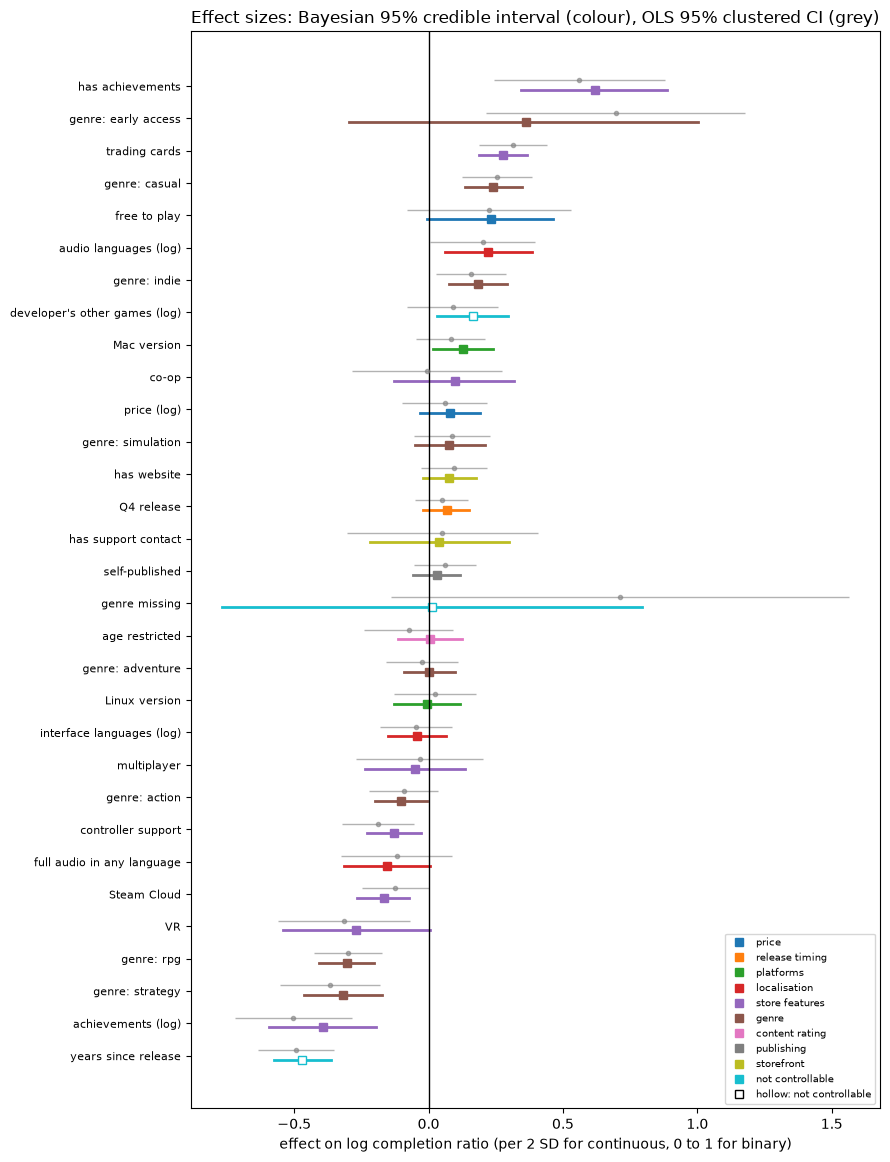

In [4]:
order = eff.sort_values("bayes_mean").index
colours = dict(zip(BLOCKS, plt.cm.tab10.colors))
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(9, 0.32 * len(order) + 1.8))
ax.errorbar(eff.loc[order, "ols_effect"], y + 0.18, xerr=[eff.loc[order, "ols_effect"] - eff.loc[order, "ols_low"],
            eff.loc[order, "ols_high"] - eff.loc[order, "ols_effect"]], fmt="o", markersize=3, capsize=0,
            color="grey", alpha=0.6, linewidth=1)
for yi, f in zip(y, order):
    c = colours[eff.loc[f, "block"]]
    ax.plot([eff.loc[f, "bayes_low"], eff.loc[f, "bayes_high"]], [yi - 0.12] * 2, color=c, linewidth=2)
    ax.plot(eff.loc[f, "bayes_mean"], yi - 0.12, "s", markersize=6, color=c,
            markerfacecolor=c if eff.loc[f, "controllable"] else "white")
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(eff.loc[order, "label"], fontsize=8)
ax.set_xlabel("effect on log completion ratio (per 2 SD for continuous, 0 to 1 for binary)")
ax.set_title("Effect sizes: Bayesian 95% credible interval (colour), OLS 95% clustered CI (grey)")
handles = [Line2D([], [], color=c, marker="s", linestyle="", label=b) for b, c in colours.items()]
handles += [Line2D([], [], color="black", marker="s", linestyle="", markerfacecolor="white", label="hollow: not controllable")]
ax.legend(handles=handles, fontsize=7, loc="lower right")
plt.tight_layout()
save_fig(fig, "04_aq3_effects")
plt.show()

### Interpretation: Effect sizes
**Author**: 
<!-- Describe which predictors have effects that are clear in both models, their direction and size as multipliers on the completion ratio, and whether OLS and the Bayesian model agree. Separate controllable from not controllable factors. Note where the per 2 SD scaling matters, and give the price caveat beside any price result. -->

## 3. Permutation importance on validation
*Code: Generated by AI Assistant*

*Written by AI Assistant*: for each predictor, its column in the validation data is shuffled and the rise in validation RMSE is recorded, holding the fitted models fixed. A predictor the models lean on for prediction raises the error when shuffled. Each predictor is shuffled 200 times, and the interval is the 2.5th to 97.5th percentile of those repeats. That interval describes the shuffling only, not sampling uncertainty in the validation games. The Bayesian prediction uses posterior means, including the developer effect for developers seen in training. Shuffling one of two collinear columns understates both, so this is read beside the VIF flag in section 4.

In [5]:
R = 200
Xv = X_val.to_numpy()
b_ols = ols.params[FEATURES].to_numpy()
b_bayes = flat(idata, "beta").mean(0)
dev_effect = (flat(idata, "sigma_dev") * flat(idata, "z_dev")).mean(0)
u_val = np.where(s.dev_val >= 0, dev_effect[np.clip(s.dev_val, 0, None)], 0.0)
models = {"ols": lambda X: ols.params["const"] + X @ b_ols,
          "bayes": lambda X: flat(idata, "intercept").mean() + X @ b_bayes + u_val}
rmse = lambda pred: np.sqrt(np.mean((y_val - pred) ** 2))
base = {m: rmse(f(Xv)) for m, f in models.items()}

rows = []
for j, feat in enumerate(FEATURES):
    rises = {m: [] for m in models}
    for _ in range(R):
        Xp = Xv.copy()
        Xp[:, j] = rng.permutation(Xp[:, j])
        for m, f in models.items():
            rises[m].append(rmse(f(Xp)) - base[m])
    row = {"feature": feat}
    for m, r in rises.items():
        row.update({f"perm_{m}": np.mean(r), f"perm_{m}_2.5%": np.quantile(r, 0.025), f"perm_{m}_97.5%": np.quantile(r, 0.975)})
    rows.append(row)
perm = pd.DataFrame(rows).set_index("feature").join(factor_map[["label", "block", "controllable"]])
perm.to_csv(config.TABLES / "04_aq3_permutation.csv")
print(f"validation RMSE before shuffling: OLS {base['ols']:.4f}, Bayesian {base['bayes']:.4f}")
perm.sort_values("perm_bayes", ascending=False).round(4).head(15)

validation RMSE before shuffling: OLS 1.0437, Bayesian 1.0308


,perm_ols,perm_ols_2.5%,perm_ols_97.5%,perm_bayes,perm_bayes_2.5%,perm_bayes_97.5%,label,block,controllable
feature,,,,,,,,,
flag_has_achievements,0.0494,0.0335,0.0646,0.0497,0.0320,0.0668,has achievements,store features,True
steam_years_since_release,0.0434,0.0217,0.0622,0.0334,0.0119,0.0515,years since release,not controllable,False
cat_trading_cards,0.0307,0.0190,0.0439,0.0279,0.0179,0.0394,trading cards,store features,True
feature_log_achievements,0.0307,0.0133,0.0494,0.0262,0.0114,0.0419,achievements (log),store features,True
genre_rpg,0.0182,0.0067,0.0293,0.0210,0.0085,0.0320,genre: rpg,genre,True
flag_has_full_audio,0.0073,0.0027,0.0118,0.0120,0.0058,0.0175,full audio in any language,localisation,True
genre_casual,0.0080,-0.0008,0.0170,0.0088,0.0003,0.0174,genre: casual,genre,True
genre_indie,0.0045,-0.0019,0.0107,0.0088,0.0014,0.0156,genre: indie,genre,True
cat_controller,0.0100,0.0009,0.0194,0.0077,0.0021,0.0138,controller support,store features,True


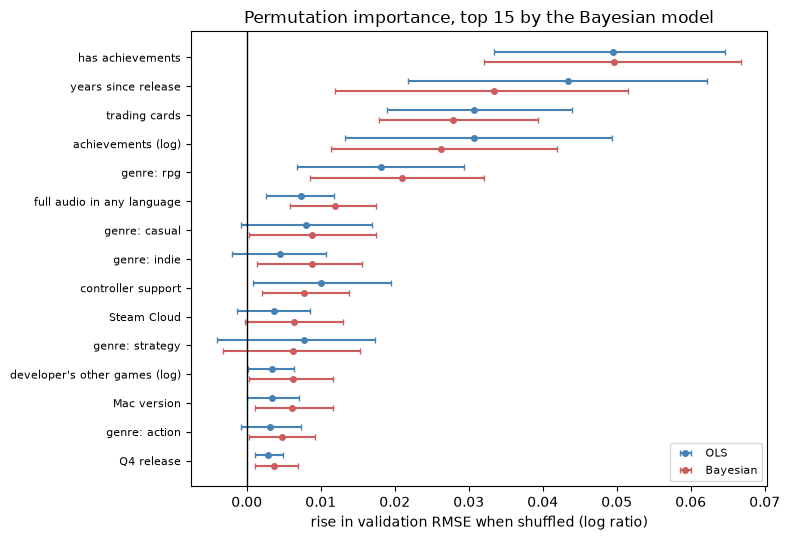

In [6]:
top = perm.sort_values("perm_bayes", ascending=False).head(15).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(8, 5.5))
for m, off, c, lab in [("ols", 0.18, "steelblue", "OLS"), ("bayes", -0.18, "indianred", "Bayesian")]:
    ax.errorbar(top[f"perm_{m}"], y + off, xerr=[top[f"perm_{m}"] - top[f"perm_{m}_2.5%"], top[f"perm_{m}_97.5%"] - top[f"perm_{m}"]],
                fmt="o", markersize=4, capsize=2, color=c, label=lab)
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(y); ax.set_yticklabels(top["label"], fontsize=8)
ax.set_xlabel("rise in validation RMSE when shuffled (log ratio)")
ax.set_title("Permutation importance, top 15 by the Bayesian model"); ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "04_aq3_permutation")
plt.show()

### Interpretation: Permutation importance
**Author**: 
<!-- Describe which predictors raise validation error most when shuffled, how large those rises are compared with the validation RMSE printed above, and whether OLS and the Bayesian model lean on the same predictors. Note any predictor that has a clear effect in section 2 but little permutation importance, or the reverse, and whether collinearity could explain it. -->

## 4. Agreement between measures, and robustness
*Code: Generated by AI Assistant*

*Written by AI Assistant*: each predictor is ranked under four measures, 1 being most important: absolute OLS effect, absolute Bayesian effect, and permutation importance in each model. Kendall's tau measures how far the rankings agree, where 1 is identical order and 0 is no relation. Two flags come from notebook 03: `survives_influence_refits` is true when the OLS interval excludes zero in the full fit and in both influence refits, and `vif_above_5` marks predictors whose coefficients may be unstable from collinearity.

In [7]:
ranks = pd.DataFrame({
    "rank_ols_effect": eff["ols_effect"].abs().rank(ascending=False),
    "rank_bayes_effect": eff["bayes_mean"].abs().rank(ascending=False),
    "rank_perm_ols": perm["perm_ols"].rank(ascending=False),
    "rank_perm_bayes": perm["perm_bayes"].rank(ascending=False),
})
refits = pd.read_csv(config.TABLES / "03_aq2_influence_refits.csv", index_col=0)
excl = [c for c in refits if c.startswith("excludes_0")]
vif = pd.read_csv(config.TABLES / "03_aq2_vif.csv", index_col=0)["VIF"]

agreement = factor_map[["label", "block", "controllable"]].join(ranks).assign(
    mean_rank=ranks.mean(axis=1),
    clear_in_both=eff["clear_in_both"],
    survives_influence_refits=refits.loc[FEATURES, excl].eq(True).all(axis=1),
    vif_above_5=vif.reindex(FEATURES) > 5,
).sort_values("mean_rank")
agreement.to_csv(config.TABLES / "04_aq3_agreement.csv")
display(ranks.corr(method="kendall").round(3))
agreement.round(1)

,rank_ols_effect,rank_bayes_effect,rank_perm_ols,rank_perm_bayes
rank_ols_effect,1.000,0.677,0.505,0.480
rank_bayes_effect,0.677,1.000,0.561,0.570
rank_perm_ols,0.505,0.561,1.000,0.837
rank_perm_bayes,0.480,0.570,0.837,1.000


,label,block,controllable,rank_ols_effect,rank_bayes_effect,rank_perm_ols,rank_perm_bayes,mean_rank,clear_in_both,survives_influence_refits,vif_above_5
feature,,,,,,,,,,,
flag_has_achievements,has achievements,store features,True,3.0,1.0,1.0,1.0,1.5,True,True,True
steam_years_since_release,years since release,not controllable,False,5.0,2.0,2.0,2.0,2.8,True,True,False
feature_log_achievements,achievements (log),store features,True,4.0,3.0,4.0,4.0,3.8,True,True,True
cat_trading_cards,trading cards,store features,True,7.0,7.0,3.0,3.0,5.0,True,True,False
genre_rpg,genre: rpg,genre,True,9.0,6.0,5.0,5.0,6.2,True,True,False
genre_strategy,genre: strategy,genre,True,6.0,5.0,8.0,11.0,7.5,True,True,False
genre_casual,genre: casual,genre,True,10.0,9.0,7.0,7.0,8.2,True,True,False
cat_controller,controller support,store features,True,13.0,16.0,6.0,9.0,11.0,True,True,False
genre_indie,genre: indie,genre,True,14.0,12.0,10.0,8.0,11.0,False,True,False


### Interpretation: Agreement and robustness
**Author**: 
<!-- Say how far the four rankings agree (Kendall's tau) and which predictors rank near the top under every measure. For those, say whether they are clear in both models, survive the influence refits from notebook 03 and are free of collinearity. Separate the controllable ones. These are the candidates AQ4 will work from. -->

## 5. Reduced model
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the reduced model is built from what a studio controls. The rule, fixed before looking at the result, keeps every controllable block that contains at least one controllable predictor marked `clear_in_both` in section 2, and keeps all of that block's columns. Factors a studio cannot control, such as game age, are left out entirely, so the comparison with the full model shows how much predictive information the controllable factors carry on their own. OLS and the Bayesian model are refitted on the kept columns and scored on the same validation games as the full models, with the same metrics as notebook 03. If no block passes, the reduced model is skipped and that is the result.

In [8]:
# Controllable blocks only: the reduced model is what a studio can act on before launch
kept_blocks = sorted(set(eff.loc[eff["clear_in_both"] & eff["controllable"], "block"]))
kept = [f for f in FEATURES if block_of[f] in kept_blocks]
print(f"blocks kept: {kept_blocks or 'none'}; predictors kept: {len(kept)} of {len(FEATURES)}")

def bayes_mu(trace, X):
    # Posterior mean prediction on validation, with seen developers' effects.
    u = (flat(trace, "sigma_dev") * flat(trace, "z_dev")).mean(0)
    u_v = np.where(s.dev_val >= 0, u[np.clip(s.dev_val, 0, None)], 0.0)
    return flat(trace, "intercept").mean() + X @ flat(trace, "beta").mean(0) + u_v

preds = {"baseline": np.full(len(y_val), y_train.mean()),
         "OLS, full": models["ols"](Xv), "Bayesian, full": models["bayes"](Xv)}
if kept:
    ols_r = sm.OLS(y_train, sm.add_constant(X_train[kept], has_constant="add")).fit(cov_type="cluster", cov_kwds={"groups": clusters})
    preds["OLS, reduced"] = ols_r.params["const"] + X_val[kept].to_numpy() @ ols_r.params[kept].to_numpy()
    with completion_model(X_train[kept], y_train, s.dev_train, s.inv_polls_train, len(s.dev_levels), COMPLETION_PRIORS):
        idata_r = pm.sample(**SAMPLE_KW)
    summ_r = az.summary(idata_r, var_names=["intercept", "beta", "sigma", "tau", "sigma_dev"])
    div_r = int(np.asarray(idata_r.sample_stats["diverging"]).sum())
    print(f"reduced Bayesian fit: max r_hat {summ_r['r_hat'].max():.3f}, min ess_bulk {summ_r['ess_bulk'].min():.0f}, divergences {div_r}")
    preds["Bayesian, reduced"] = bayes_mu(idata_r, X_val[kept].to_numpy())

def score(pred):
    err = y_val - pred
    return {"predictors": np.nan, "RMSE": np.sqrt(np.mean(err ** 2)), "MAE": np.mean(np.abs(err)),
            "R2_vs_baseline": 1 - np.sum(err ** 2) / np.sum((y_val - preds["baseline"]) ** 2),
            "typical_factor_error": np.exp(np.median(np.abs(err)))}

reduced_table = pd.DataFrame({name: score(p) for name, p in preds.items()}).T
reduced_table["predictors"] = [0, len(FEATURES), len(FEATURES)] + [len(kept)] * (len(preds) - 3)
reduced_table.insert(0, "validation_games", len(y_val))
reduced_table.to_csv(config.TABLES / "04_aq3_reduced_vs_full.csv")
reduced_table.round(4)

NUTS[numpyro]: [intercept, beta, sigma_dev, z_dev, sigma, tau]


blocks kept: ['genre', 'store features']; predictors kept: 16 of 31


reduced Bayesian fit: max r_hat 1.008, min ess_bulk 788, divergences 0


,validation_games,predictors,RMSE,MAE,R2_vs_baseline,typical_factor_error
baseline,482,0,1.1210,0.8263,0.0000,1.8581
"OLS, full",482,31,1.0437,0.7453,0.1332,1.7409
"Bayesian, full",482,31,1.0308,0.7298,0.1544,1.7170
"OLS, reduced",482,16,1.0560,0.7646,0.1126,1.7692
"Bayesian, reduced",482,16,1.0362,0.7469,0.1456,1.7477


### Interpretation: Reduced model
**Author**: 
<!-- Say which controllable blocks the rule kept and how many predictors that leaves. Compare the reduced models with the full models and the baseline on validation error. If the reduced models do about as well with fewer predictors, say so; if they do worse, say by how much. State the reduced Bayesian fit's convergence before reading its error. -->

## 6. Effects a studio can read
*Code: Generated by AI Assistant*

*Written by AI Assistant*: for the controllable predictors marked `clear_in_both`, the Bayesian model's predicted completion ratio is shown on its original scale. Every other predictor is held at a reference game: continuous predictors at their training mean, binary ones at their most common value, and the developer effect at zero, the population average. Continuous predictors are drawn against their raw value over the middle 95% of training games. Binary predictors are shown off and on. The achievements flag and the achievement count are linked, so a game with 0 achievements also has the flag off, and the flag's "no" bar has 0 achievements. Bands and bars are 90% credible intervals for the typical ratio of such a game, not for one game's ratio.

Price is the price at scrape time, not the launch price, so a price curve describes what games at each current price look like, not what a studio should charge.

controllable predictors clear in both models: ['achievements (log)', 'has achievements', 'controller support', 'trading cards', 'genre: casual', 'genre: strategy', 'genre: rpg']


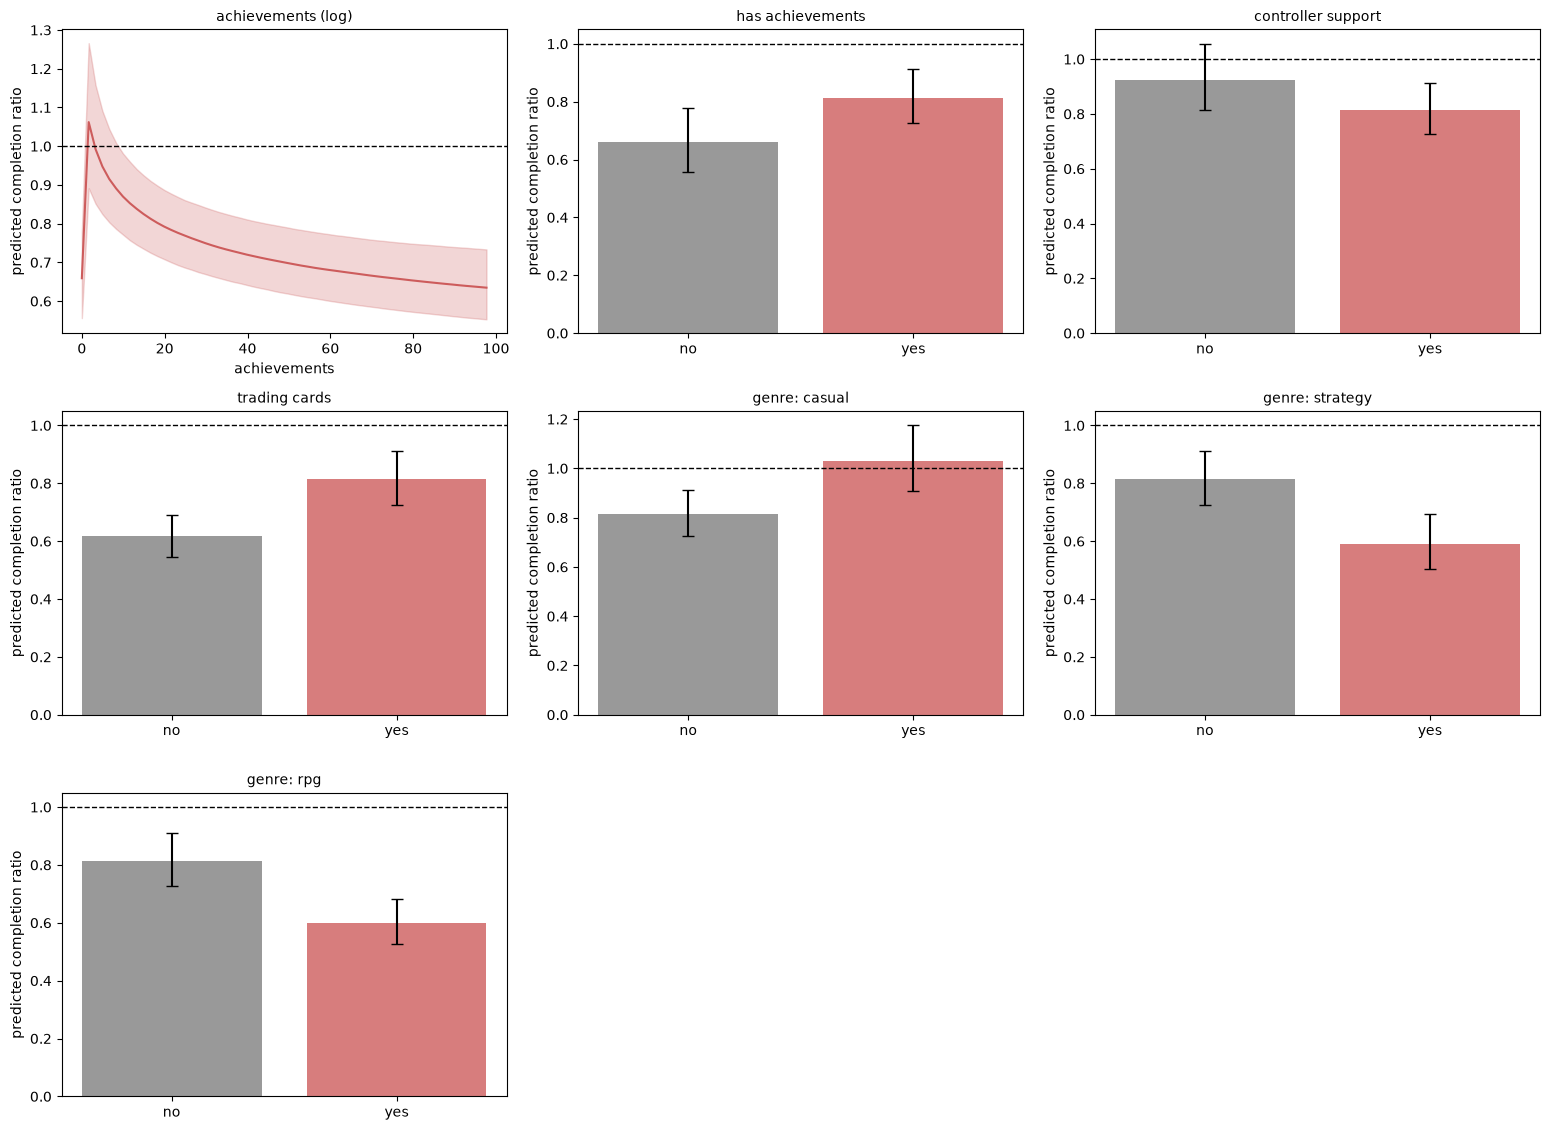

,feature,value,median_ratio,ratio_5%,ratio_95%
0,feature_log_achievements,0.0,0.659,0.556,0.779
1,feature_log_achievements,97.7,0.635,0.553,0.733
2,flag_has_achievements,0.0,0.659,0.556,0.779
3,flag_has_achievements,1.0,0.813,0.725,0.911
4,cat_controller,0.0,0.924,0.814,1.056
5,cat_controller,1.0,0.813,0.725,0.911
6,cat_trading_cards,0.0,0.616,0.547,0.692
7,cat_trading_cards,1.0,0.813,0.725,0.911
8,genre_casual,0.0,0.813,0.725,0.911
9,genre_casual,1.0,1.031,0.906,1.174


In [9]:
RAW = {"feature_log_price": ("steam_price", "price at scrape time (USD)"),
       "feature_log_language_count_imputed": ("feature_language_count_imputed", "interface languages"),
       "feature_log_audio_language_count": ("steam_audio_language_count", "audio languages"),
       "feature_log_achievements": ("steam_achievements", "achievements")}
# The flag is 1 exactly when the count is above 0, so the two move together in every panel.
LINKED = {"flag_has_achievements": "feature_log_achievements"}
show = eff.index[eff["clear_in_both"] & eff["controllable"]].tolist()
print(f"controllable predictors clear in both models: {[factor_map.loc[f, "label"] for f in show] or 'none'}")

a_d, b_d = flat(idata, "intercept"), flat(idata, "beta")              # draws x 1, draws x features
x_ref = pd.Series(0.0, index=FEATURES)
for f in s.binary:
    x_ref[f] = float(s.train[f].mode().iloc[0])
mu_ref = a_d[:, 0] + b_d @ x_ref.to_numpy()

partial_rows = []
if show:
    ncol = min(3, len(show)); nrow = int(np.ceil(len(show) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(5.2 * ncol, 3.8 * nrow), squeeze=False)
    for ax, f in zip(axes.ravel(), show):
        j = FEATURES.index(f)
        if f in s.continuous:
            raw_col, raw_label = RAW[f]
            lo, hi = np.quantile(s.train[raw_col], [0.025, 0.975])
            grid = np.linspace(lo, hi, 60)
            z = (np.log1p(grid) - s.centre[f]) / s.scale[f]
            mu = mu_ref[:, None] + b_d[:, [j]] * (z[None, :] - x_ref[f])
            for flag, count in LINKED.items():
                if count == f:
                    k = FEATURES.index(flag)
                    mu = mu + b_d[:, [k]] * ((grid > 0).astype(float)[None, :] - x_ref[flag])
            ratio = np.exp(mu)
            ax.plot(grid, np.median(ratio, 0), color="indianred")
            ax.fill_between(grid, *np.quantile(ratio, [0.05, 0.95], axis=0), color="indianred", alpha=0.25)
            ax.set_xlabel(raw_label)
            for g, r in zip(grid[[0, -1]], ratio[:, [0, -1]].T):
                partial_rows.append({"feature": f, "value": g, "median_ratio": np.median(r),
                                     "ratio_5%": np.quantile(r, 0.05), "ratio_95%": np.quantile(r, 0.95)})
        else:
            vals = []
            for v in (0, 1):
                mu = mu_ref + b_d[:, j] * (v - x_ref[f])
                if f in LINKED and v == 0:
                    count = LINKED[f]
                    mu = mu + b_d[:, FEATURES.index(count)] * ((0 - s.centre[count]) / s.scale[count] - x_ref[count])
                r = np.exp(mu)
                vals.append(r)
                partial_rows.append({"feature": f, "value": v, "median_ratio": np.median(r),
                                     "ratio_5%": np.quantile(r, 0.05), "ratio_95%": np.quantile(r, 0.95)})
            med = [np.median(r) for r in vals]
            err = [[m - np.quantile(r, 0.05) for m, r in zip(med, vals)], [np.quantile(r, 0.95) - m for m, r in zip(med, vals)]]
            ax.bar(["no", "yes"], med, yerr=err, capsize=4, color=["grey", "indianred"], alpha=0.8)
        ax.axhline(1, color="black", linestyle="--", linewidth=1)
        ax.set_ylabel("predicted completion ratio"); ax.set_title(factor_map.loc[f, "label"], fontsize=10)
    for ax in axes.ravel()[len(show):]:
        ax.set_visible(False)
    plt.tight_layout()
    save_fig(fig, "04_aq3_partial_effects")
    plt.show()
partial = pd.DataFrame(partial_rows)
partial.to_csv(config.TABLES / "04_aq3_partial_effects.csv", index=False)
partial.round(3)

### Interpretation: Effects a studio can read
**Author**: 
<!-- For each factor shown, describe the predicted completion ratio of the reference game across the factor's range, or with and without it, and how wide the credible interval is. Say what the dashed line at a ratio of 1 means for each. Keep the price caveat beside any price result. How these feed decisions is AQ4. -->

## Save for later stages
*Code: Generated by AI Assistant*

*Written by AI Assistant*: one row per predictor with its block, controllable flag, effects, ranks and robustness flags, for AQ4.

In [10]:
importance = eff.join(perm[["perm_ols", "perm_bayes"]]).join(
    agreement[["rank_ols_effect", "rank_bayes_effect", "rank_perm_ols", "rank_perm_bayes", "mean_rank",
               "survives_influence_refits", "vif_above_5"]])
importance["in_reduced_model"] = importance.index.isin(kept)
importance.reset_index().to_parquet(config.INTERIM / "04_aq3_importance.parquet", index=False)
print(f"rows out: {len(importance)} predictors -> data/interim/04_aq3_importance.parquet")
print(f"figures: {sorted(p.name for p in config.FIGURES.glob('04_aq3_*.png'))}")
print(f"tables : {sorted(p.name for p in config.TABLES.glob('04_aq3_*.csv'))}")

rows out: 31 predictors -> data/interim/04_aq3_importance.parquet
figures: ['04_aq3_effects.png', '04_aq3_partial_effects.png', '04_aq3_permutation.png']
tables : ['04_aq3_agreement.csv', '04_aq3_effects.csv', '04_aq3_factor_map.csv', '04_aq3_partial_effects.csv', '04_aq3_permutation.csv', '04_aq3_reduced_vs_full.csv']
